In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

# Gold vs Green line of correlation tme in dodecane plot. 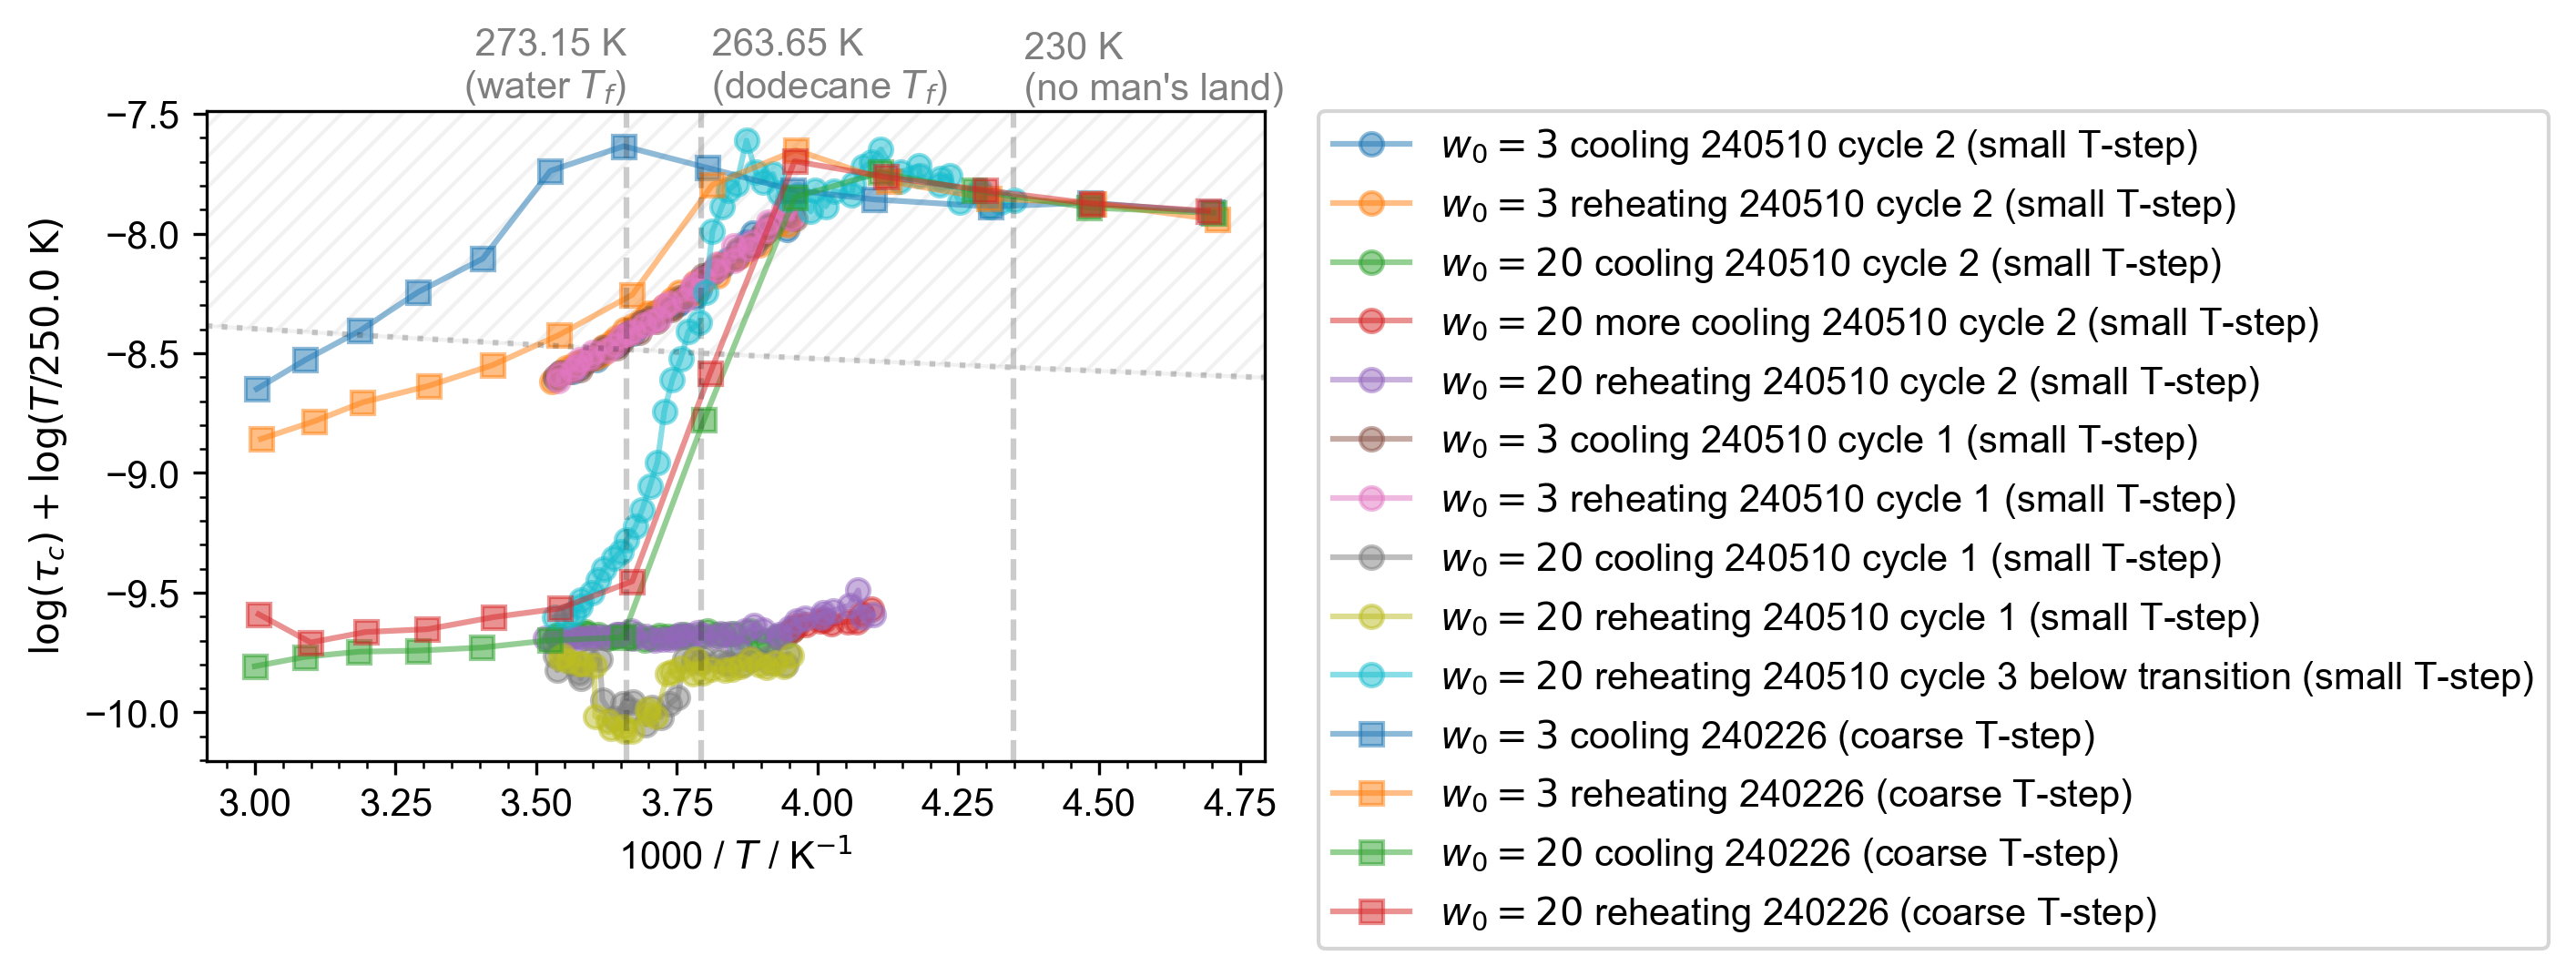

In [2]:
# gold line 
# label="$w_0=20$ reheating 240510 cycle 1 (small T-step)"
#    fname="240510_TS_C10_W20_run2.DSC"
d1 = find_file("240510_TS_C10_W20_run2.DSC", exp_type="francklab_esr/romana") 

In [3]:
# green line
# label="$w_0=20$ cooling 240510 cycle 2 (small T-step)"
#    fname="240510_TS_C10_W20_run3.DSC"
d2 = find_file("240510_TS_C10_W20_run3.DSC", exp_type="francklab_esr/romana") 

In [4]:
d1.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [5]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [6]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [7]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

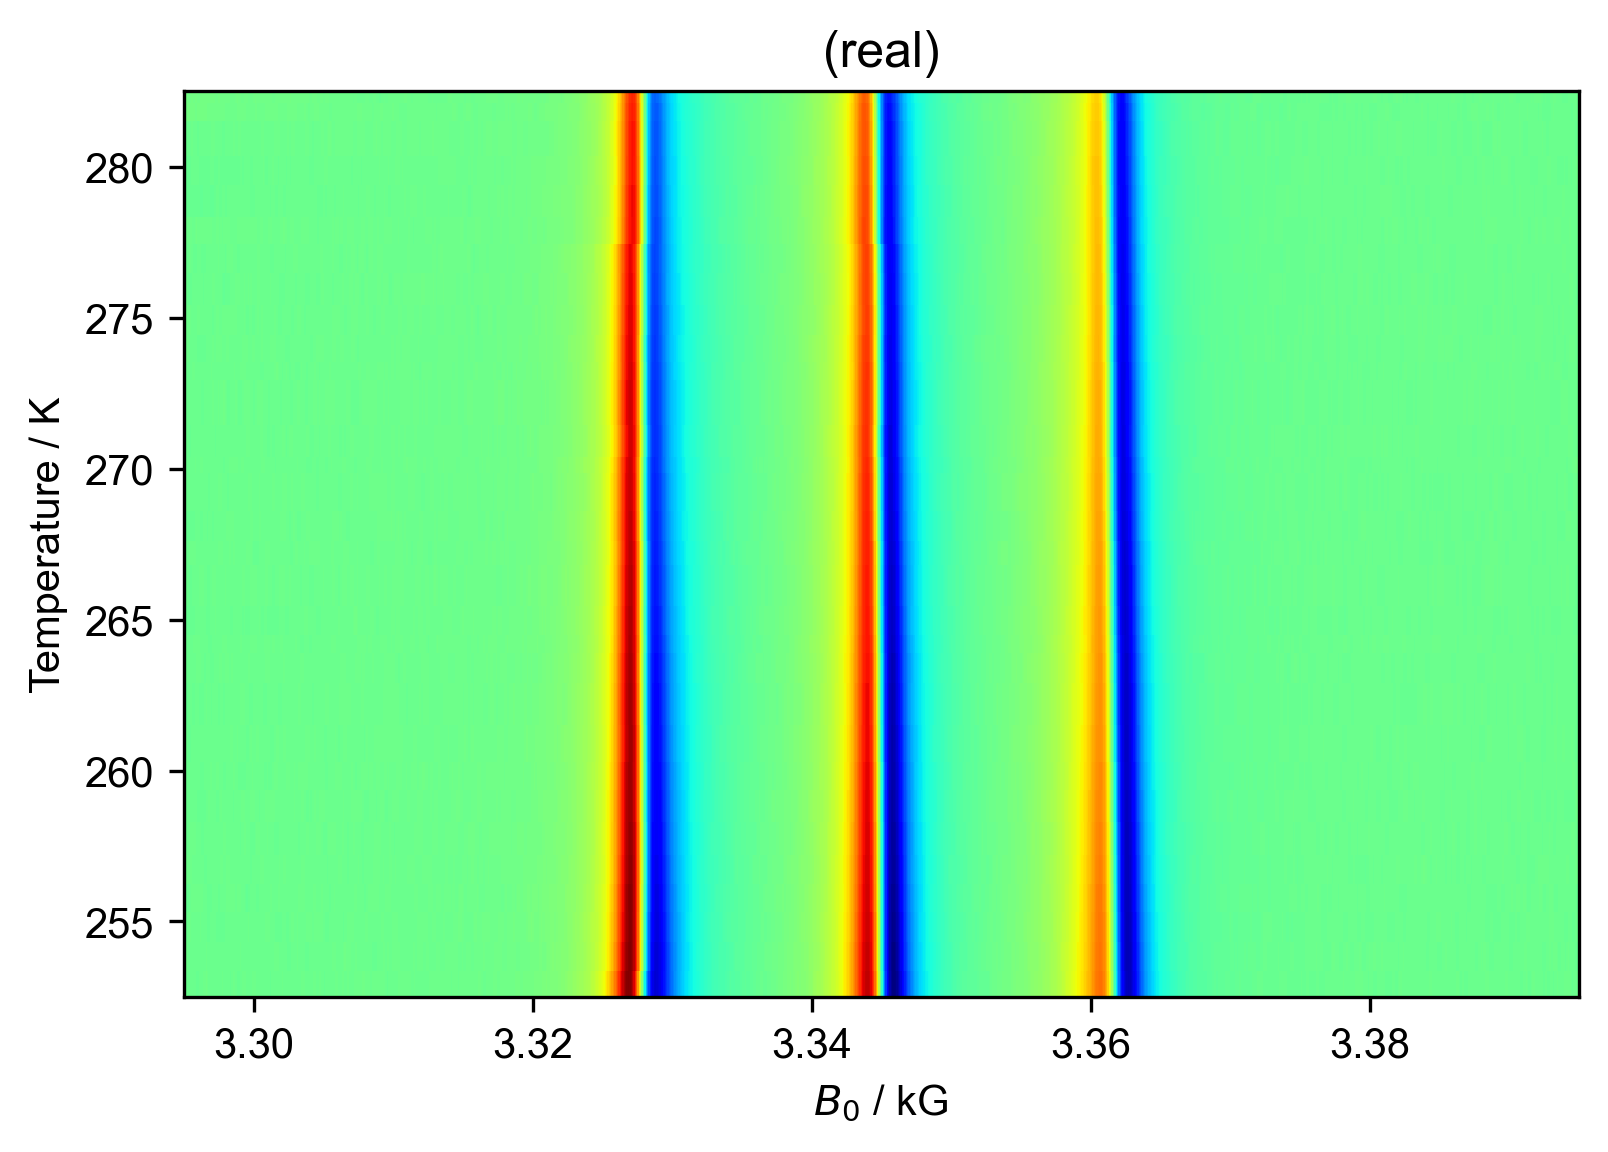

In [8]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()

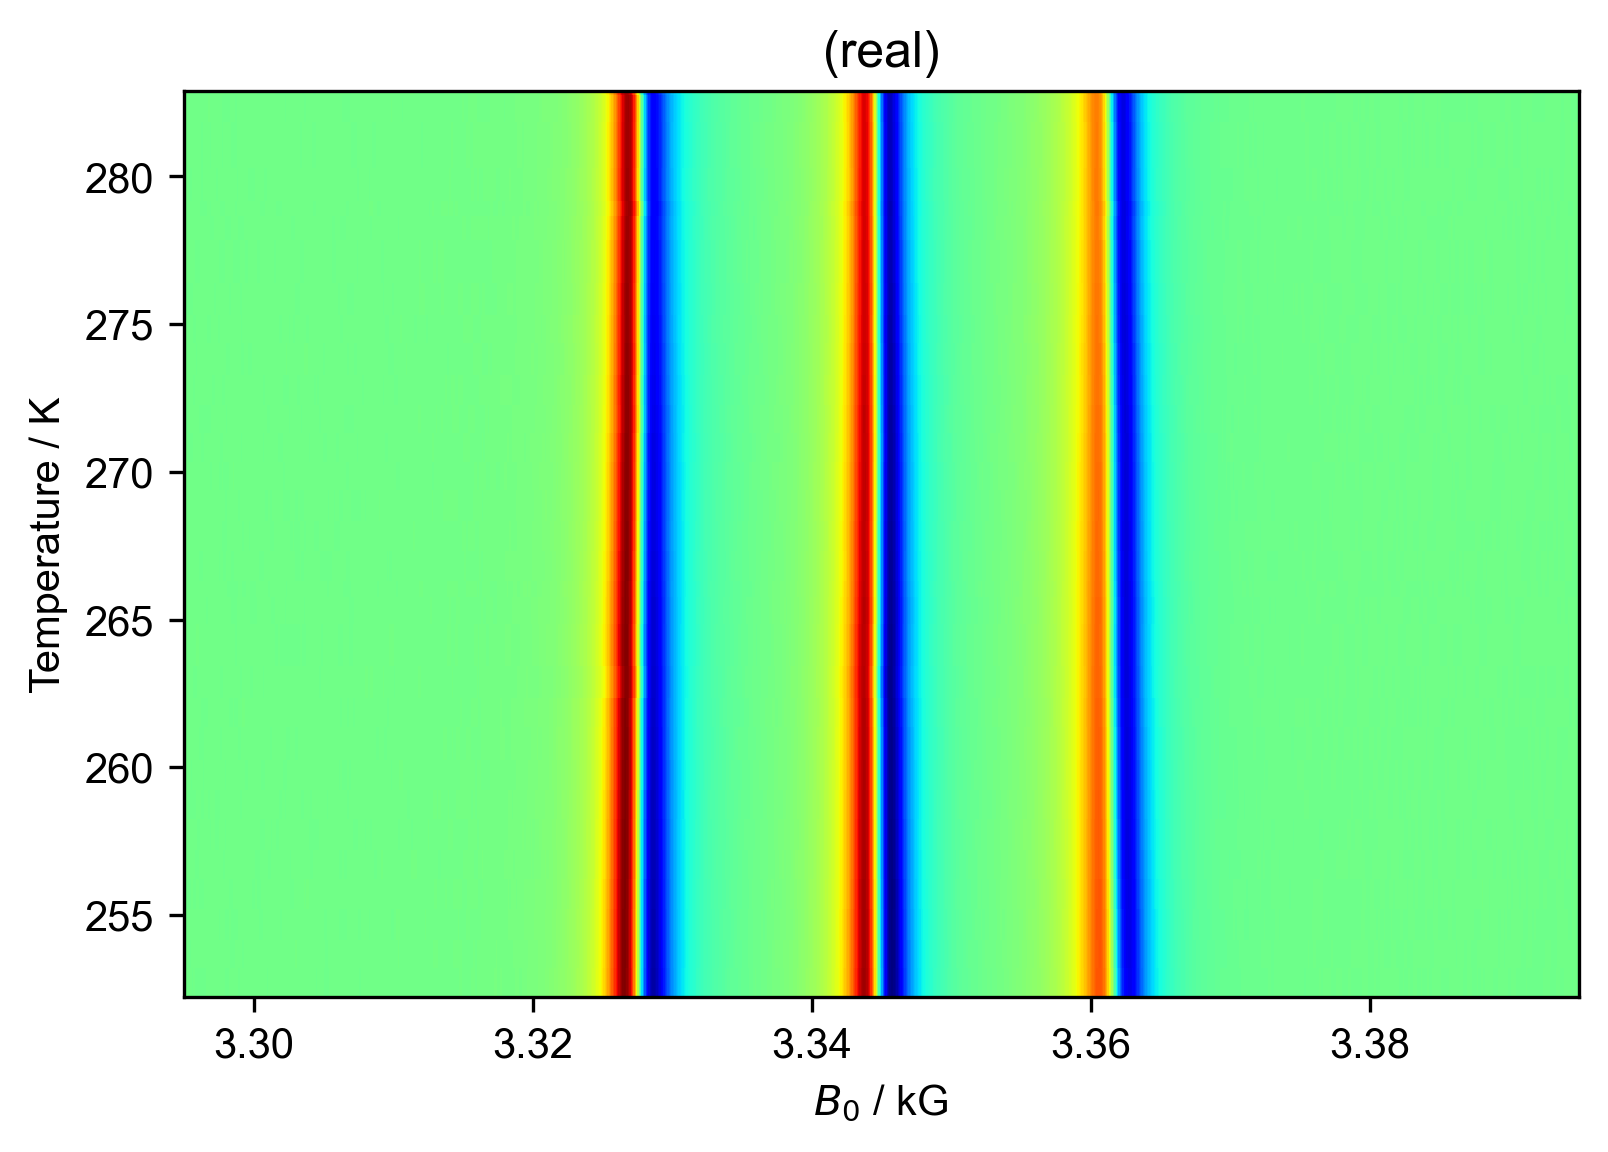

In [9]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()

[252.931 253.817 254.821 255.823 256.679 257.705 258.86  259.883 260.694
 262.354 263.462 264.347 264.633 266.295 267.343 267.835 269.382 270.307
 270.461 272.457 273.435 273.612 275.239 275.582 277.411 277.5   279.163
 279.608 281.131 281.917 282.31 ]
[252.705 253.685 254.649 255.77  256.692 257.692 258.782 259.647 260.878
 261.832 262.863 263.983 265.737 265.815 266.813 267.822 268.88  269.896
 270.769 271.844 272.685 273.841 274.871 275.723 277.044 278.643 278.706
 279.62  280.978 282.691 282.817]


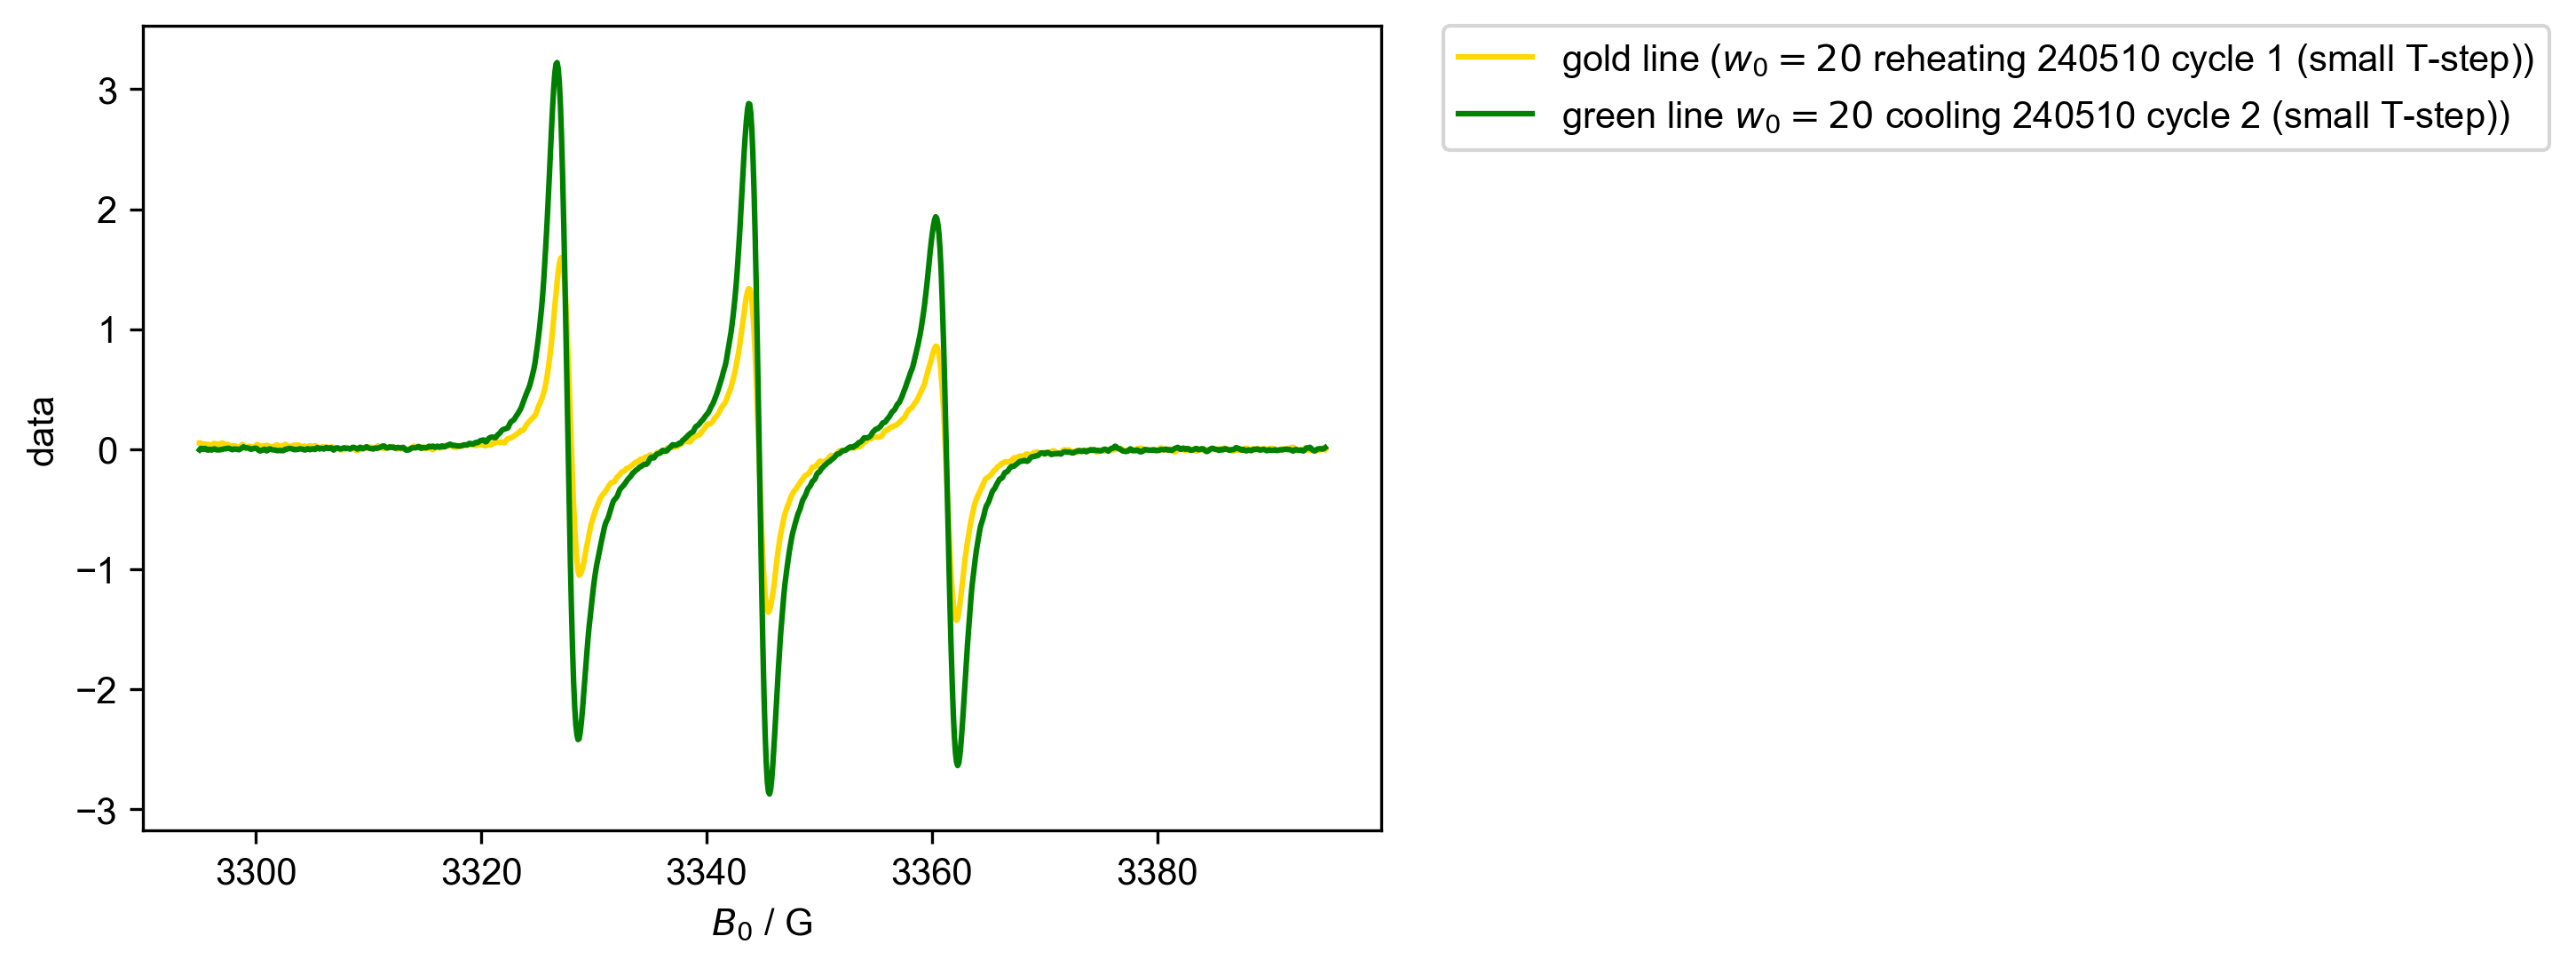

In [17]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300)
plot(d1["Temperature":283], color='gold', label="gold line ($w_0=20$ reheating 240510 cycle 1 (small T-step))")
plot(d2["Temperature":283], color='green', label="green line $w_0=20$ cooling 240510 cycle 2 (small T-step))")
fancy_legend()

[252.931 253.817 254.821 255.823 256.679 257.705 258.86  259.883 260.694
 262.354 263.462 264.347 264.633 266.295 267.343 267.835 269.382 270.307
 270.461 272.457 273.435 273.612 275.239 275.582 277.411 277.5   279.163
 279.608 281.131 281.917 282.31 ]
[252.705 253.685 254.649 255.77  256.692 257.692 258.782 259.647 260.878
 261.832 262.863 263.983 265.737 265.815 266.813 267.822 268.88  269.896
 270.769 271.844 272.685 273.841 274.871 275.723 277.044 278.643 278.706
 279.62  280.978 282.691 282.817]


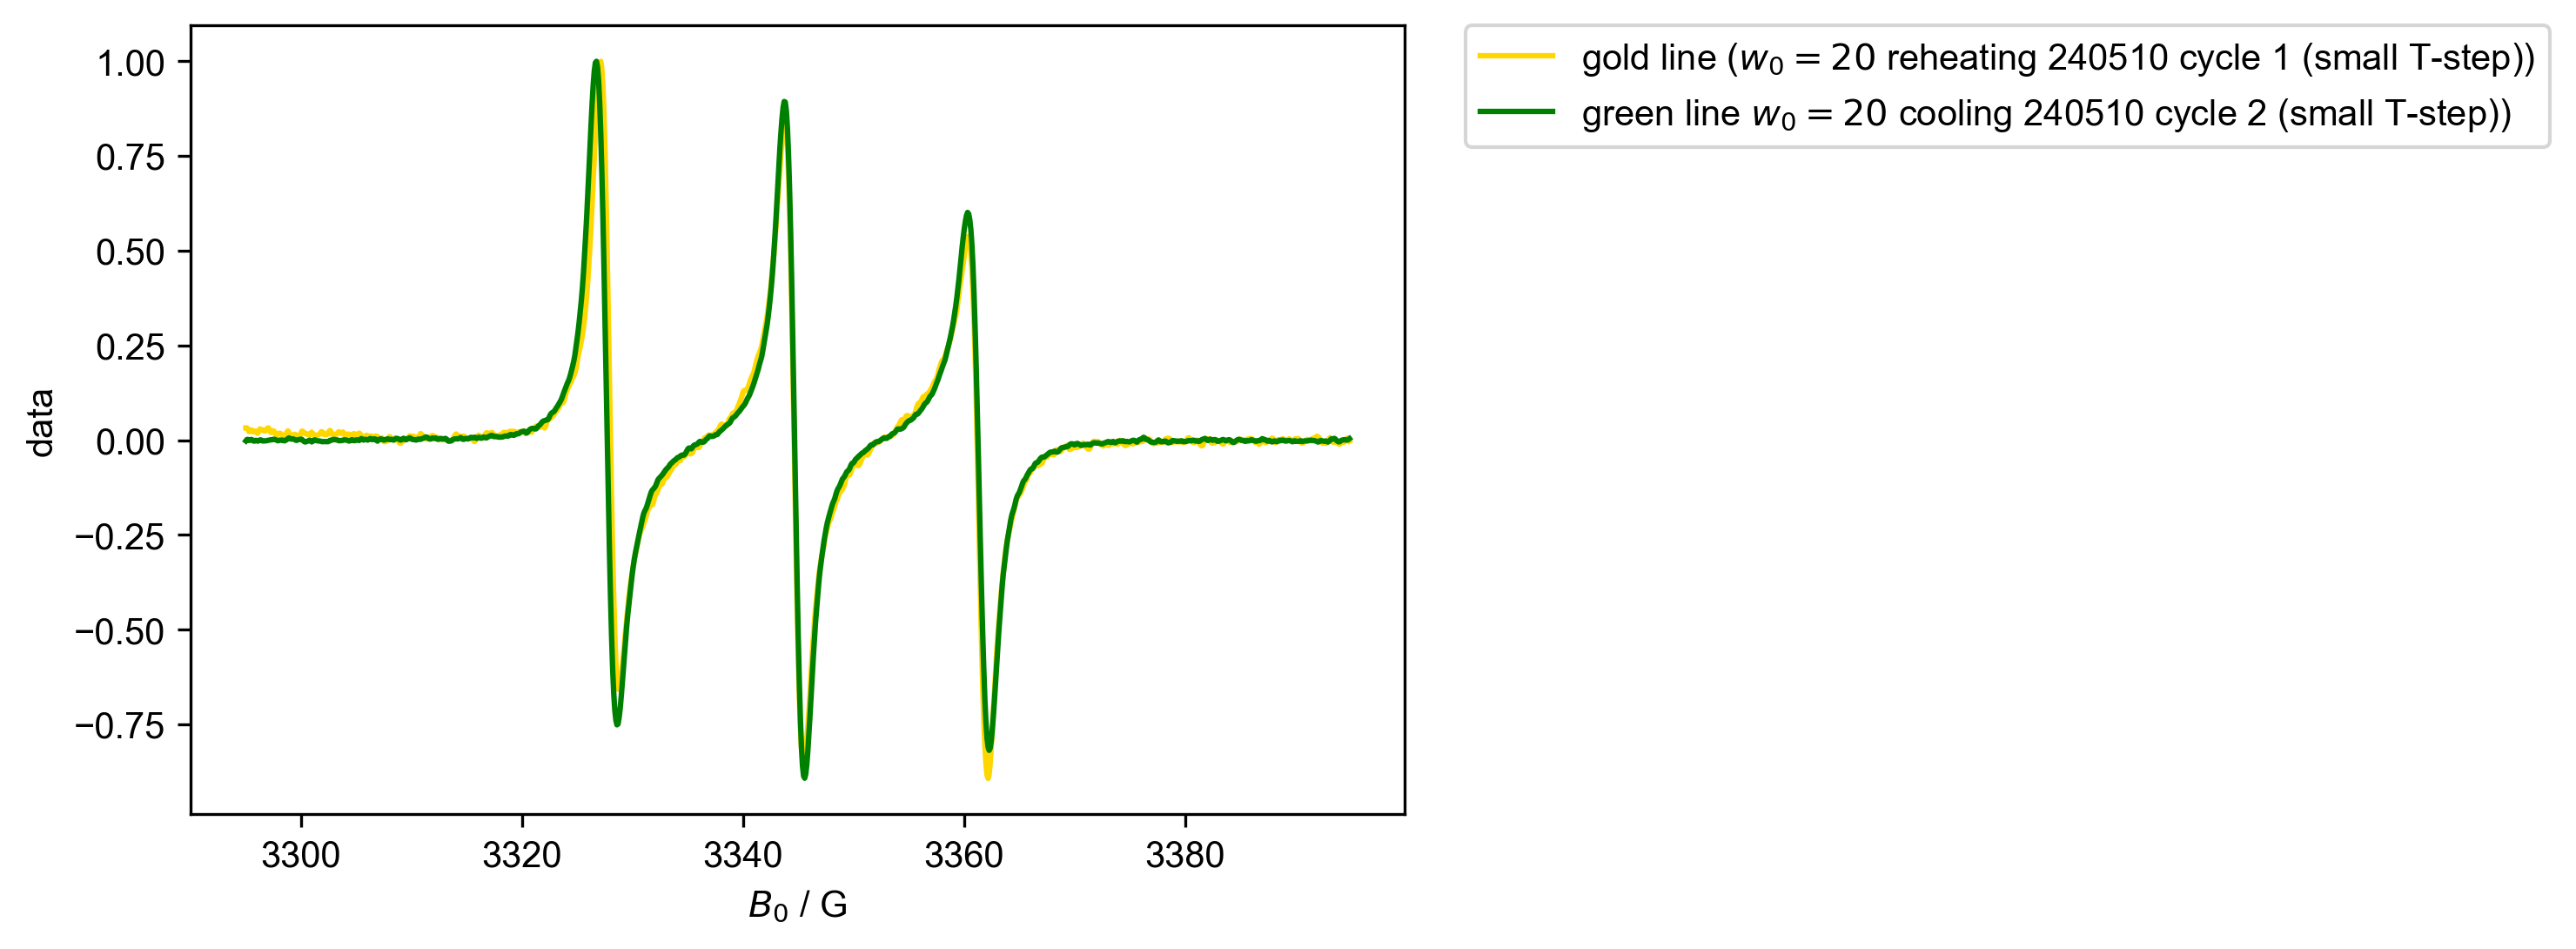

In [19]:
#Normalized near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300)
plot(d1["Temperature": 283] / d1["Temperature": 283].max(),  color='gold', label="gold line ($w_0=20$ reheating 240510 cycle 1 (small T-step))")
plot(d2["Temperature": 283] / d2["Temperature": 283].max(), color='green', label="green line $w_0=20$ cooling 240510 cycle 2 (small T-step))")
fancy_legend()

In [11]:
print(d1.get_prop())

dict_keys(['DSRC', 'BSEQ', 'IKKF', 'XTYP', 'YTYP', 'ZTYP', 'IRFMT', 'YFMT', 'YPTS', 'YMIN', 'YWID', 'TITL', 'IRNAM', 'XNAM', 'IRUNI', 'OPER', 'DATE', 'TIME', 'CMNT', 'SAMP', 'SFOR', 'STAG', 'EXPT', 'OXS1', 'AXS1', 'AXS2', 'AXS3', 'A1CT', 'A1SW', 'MWFQ', 'MWPW', 'A2RS', 'A2LL', 'A2SW', 'AVGS', 'SPTP', 'RCAG', 'RCHM', 'B0MA', 'B0MF', 'RCPH', 'RCOF', 'A1RS', 'RCTC', '', '.DVC', 'AllegroMode', 'CenterField', 'Delay', 'FieldFlyback', 'FieldWait', 'GFactor', 'MeasuringHall', 'SetToSampleG', 'StaticFieldMon', 'SweepDirection', 'SweepWidth', 'WidthTM', 'FrequencyMon', 'QMonitBridge', 'AcqFineTuning', 'AcqScanFTuning', 'AcqSliceFTuning', 'BridgeCalib', 'Power', 'PowerAtten', 'QValue', 'Flyback', 'NbCycles', 'NbPoints', 'StartValue', 'SweepData', 'sweepType', 'BaselineCorr', 'NbScansAcc', 'NbScansDone', 'NbScansToDo', 'ReplaceMode', 'SmoothMode', 'SmoothPoints', 'AFCTrap', 'AllowShortCt', 'Calibrated', 'ConvFact', 'ConvTime', 'DModDetectSCT', 'DoubleModAcc', 'DoubleModFreq', 'DoubleMode', 'DualD

In [12]:
print(d1.get_prop('MWFQ')/1e9)
print(d1.get_prop('SweepWidth'))
# for checking against Multicomponent
print("center field",d1['$B_0$'][r_[0,-1]].mean().item())
print("field width",np.diff(d1['$B_0$'][r_[0,-1]]).item())

9.438441
(1.0, 'K')
center field 3344.951172
field width 99.90234400000008


In [13]:
print(d2.get_prop('MWFQ')/1e9)
print(d2.get_prop('SweepWidth'))
# for checking against Multicomponent
print("center field",d2['$B_0$'][r_[0,-1]].mean().item())
print("field width",np.diff(d2['$B_0$'][r_[0,-1]]).item())

9.438063
(1.0, 'K')
center field 3344.951172
field width 99.90234400000008
